In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7043, 21)


In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [11]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [13]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [14]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges dtype: float64
Missing TotalCharges: 11


In [15]:
df = df.dropna(subset=["TotalCharges"])

print("Dataset shape after cleaning:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Dataset shape after cleaning: (7032, 21)
Missing TotalCharges: 0


In [16]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## Analyze Churn by Tenure

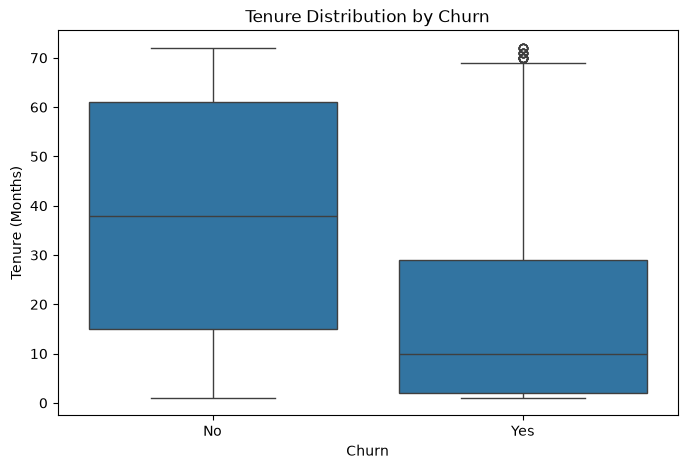

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

## Analyze Monthly Charges by Churn

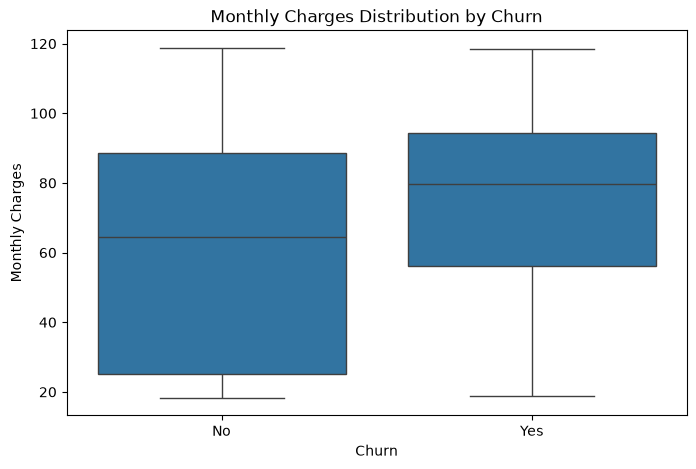

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

## Analyze Churn by Contract Type

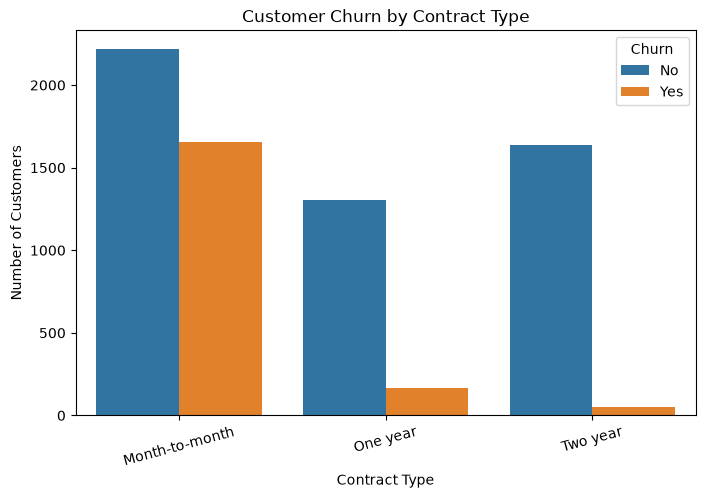

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

## Analyze Churn by Internet Service

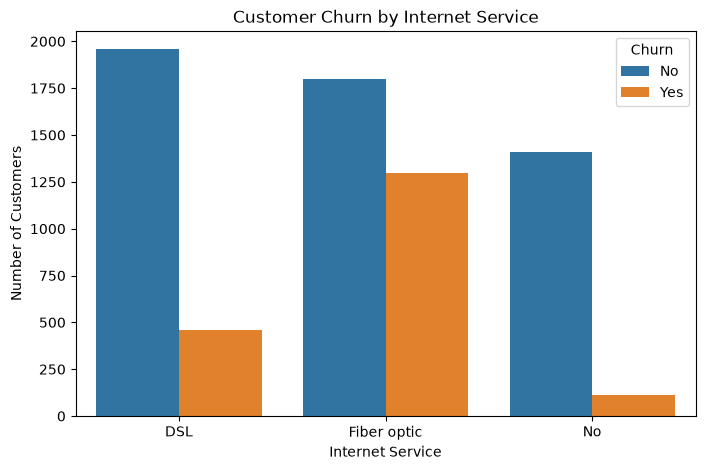

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Payment Method

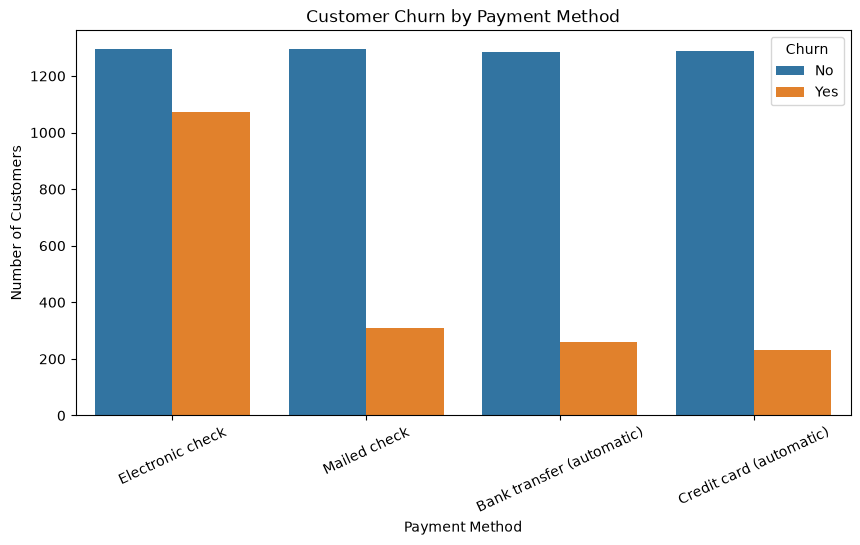

In [21]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.show()

## Analyze Churn by Senior Citizen

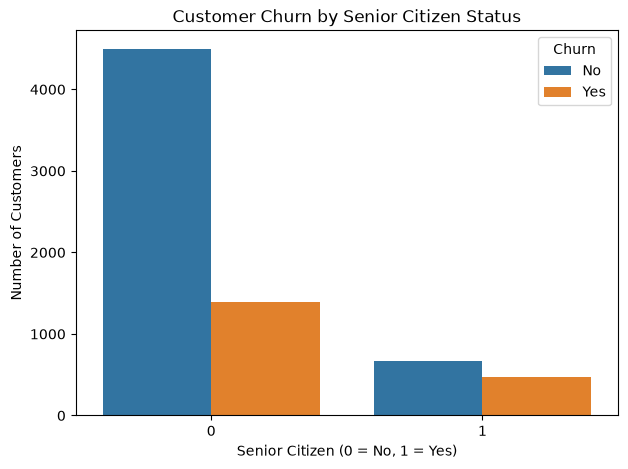

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Tenure Groups

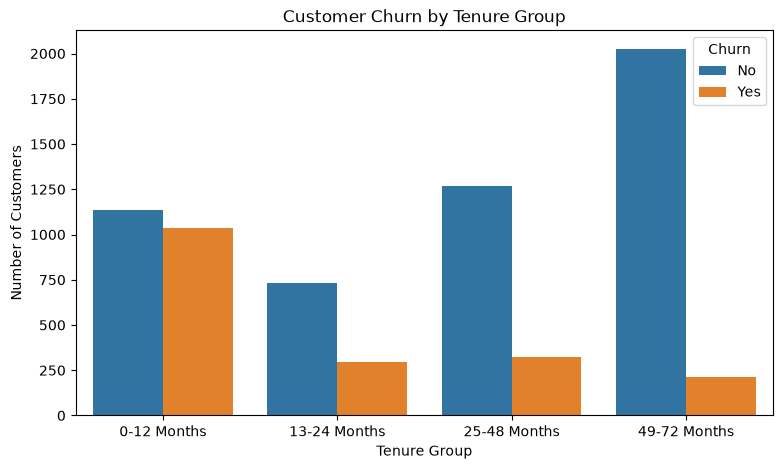

In [23]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="TenureGroup",
    hue="Churn"
)

plt.title("Customer Churn by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.show()

## Check Churn by Online Security

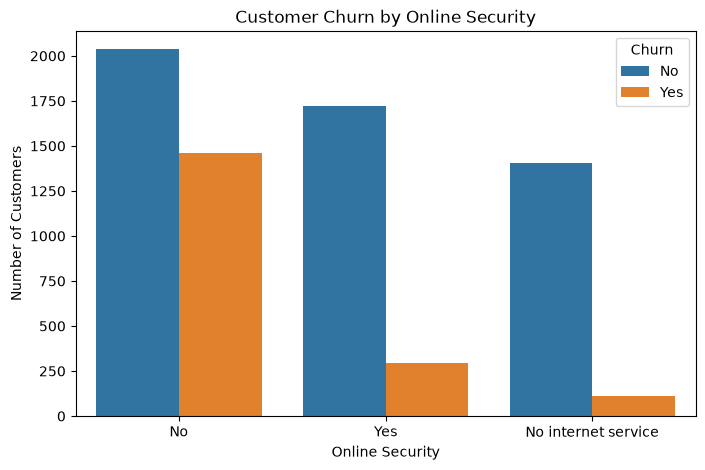

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Customer Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Tech Support

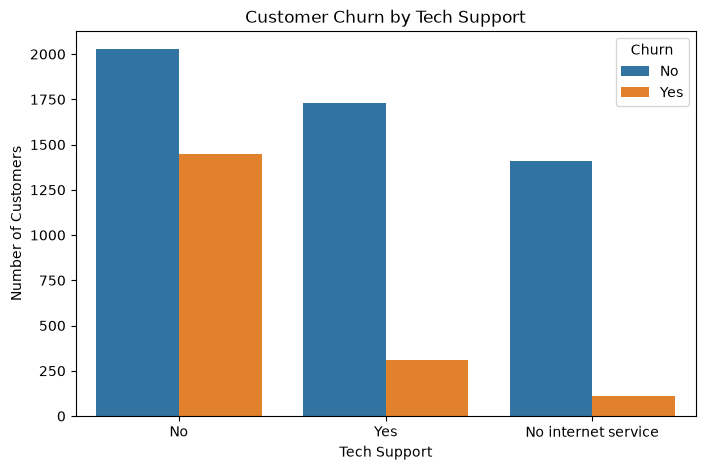

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn"
)

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Paperless Billing

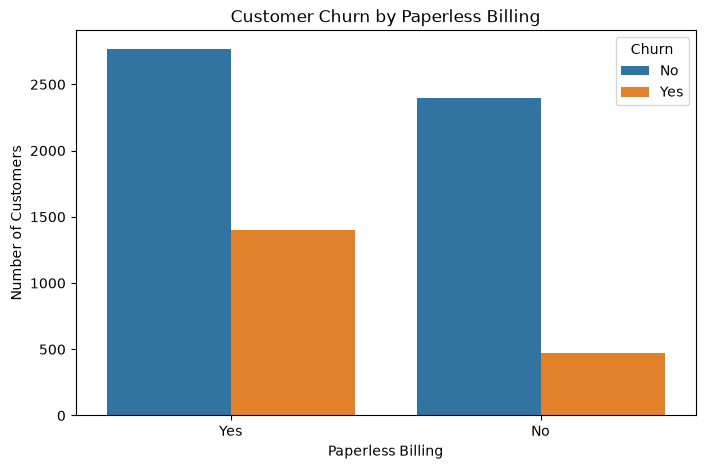

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="PaperlessBilling",
    hue="Churn"
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Gender

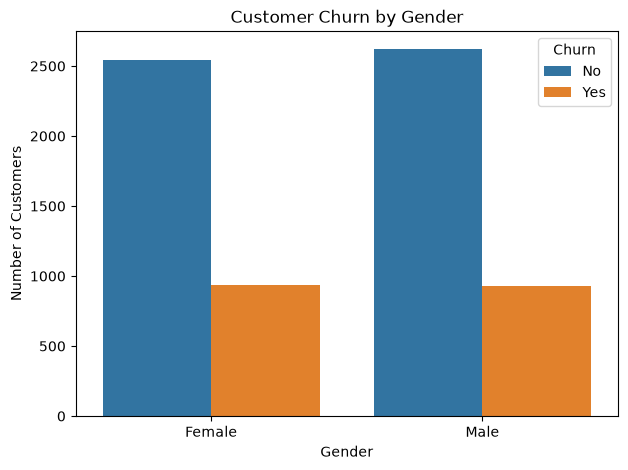

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Partner Status

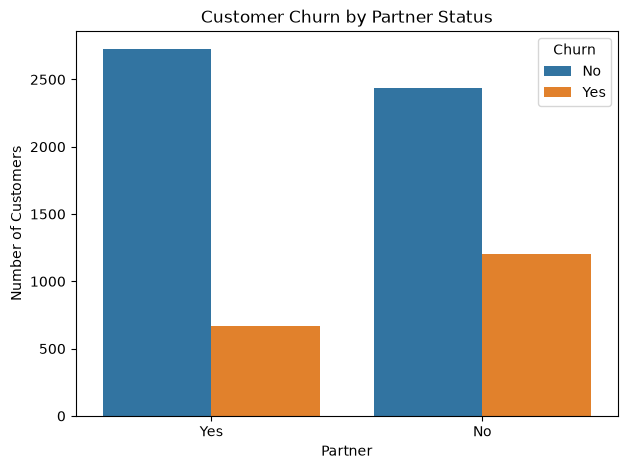

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn"
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Dependents

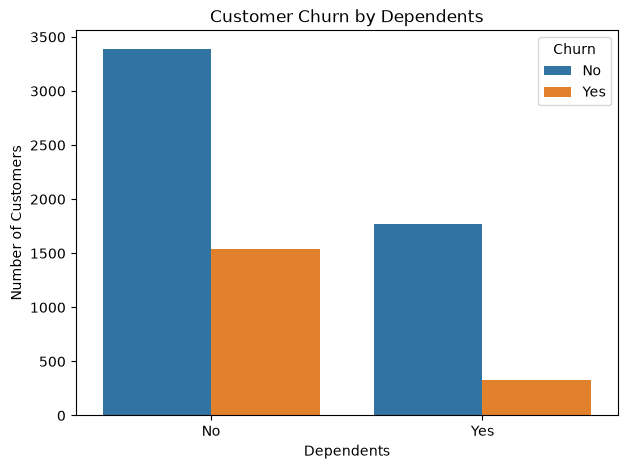

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Dependents",
    hue="Churn"
)

plt.title("Customer Churn by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Phone Service

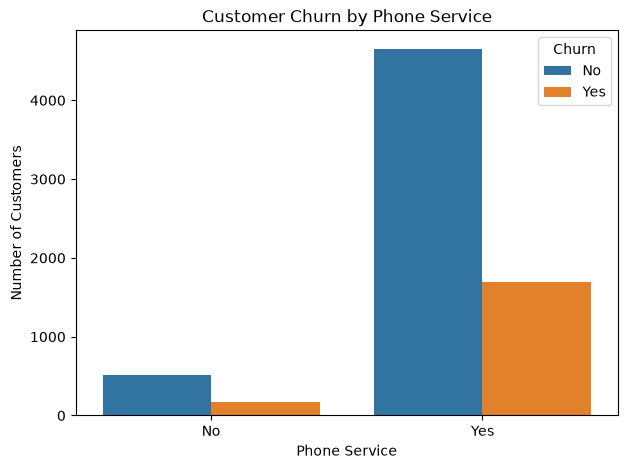

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="PhoneService",
    hue="Churn"
)

plt.title("Customer Churn by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Multiple Lines

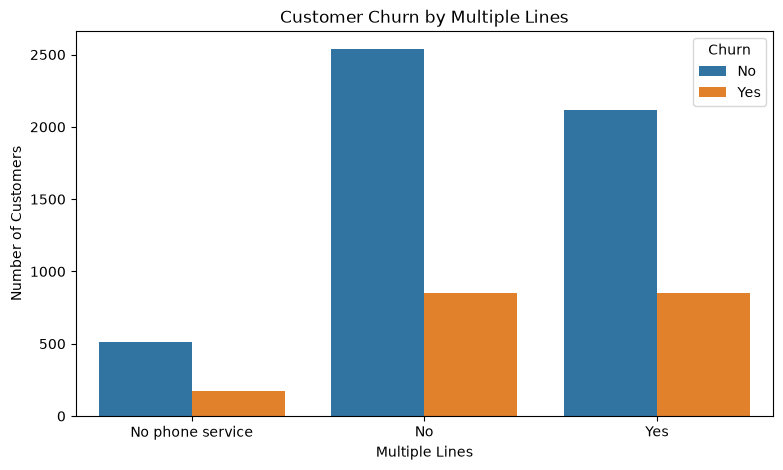

In [31]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="MultipleLines",
    hue="Churn"
)

plt.title("Customer Churn by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Online Backup

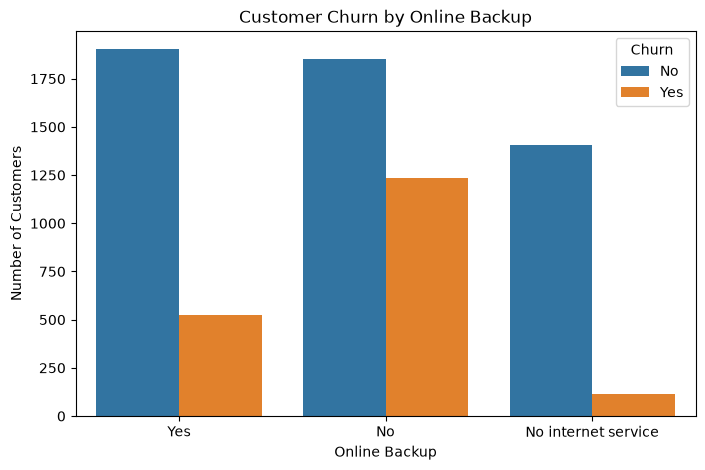

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineBackup",
    hue="Churn"
)

plt.title("Customer Churn by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Device Protection

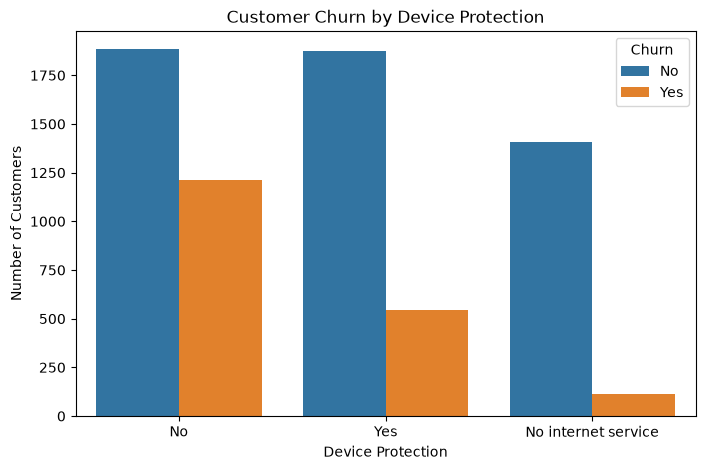

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="DeviceProtection",
    hue="Churn"
)

plt.title("Customer Churn by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Streaming TV

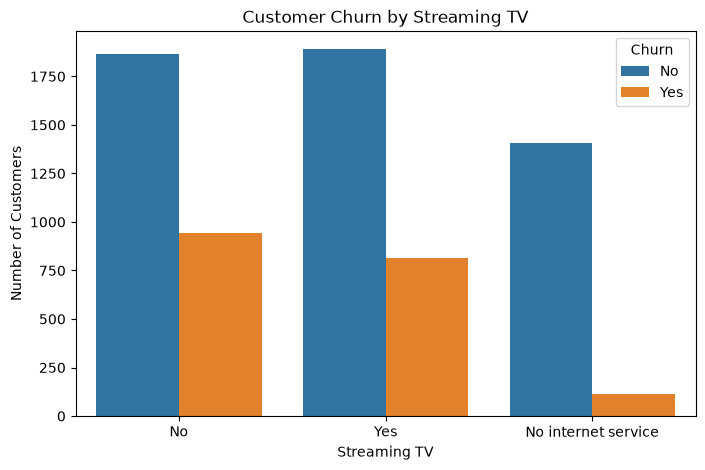

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="StreamingTV",
    hue="Churn"
)

plt.title("Customer Churn by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Streaming Movies

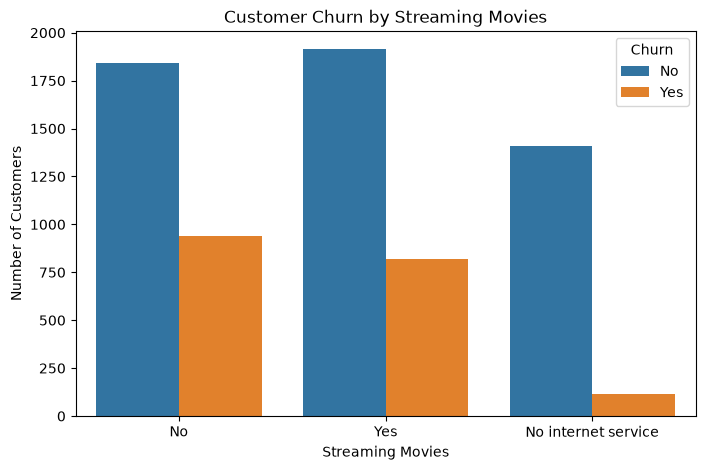

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="StreamingMovies",
    hue="Churn"
)

plt.title("Customer Churn by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Number of Customers")
plt.show()

## Analyze Churn by Customer Services

In [36]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = (
    df[service_columns]
    .apply(lambda row: (row == "Yes").sum(), axis=1)
)

print(df[["customerID", "TotalServices", "Churn"]].head())

   customerID  TotalServices Churn
0  7590-VHVEG              1    No
1  5575-GNVDE              2    No
2  3668-QPYBK              2   Yes
3  7795-CFOCW              3    No
4  9237-HQITU              0   Yes


## Analyze Churn by Total Services

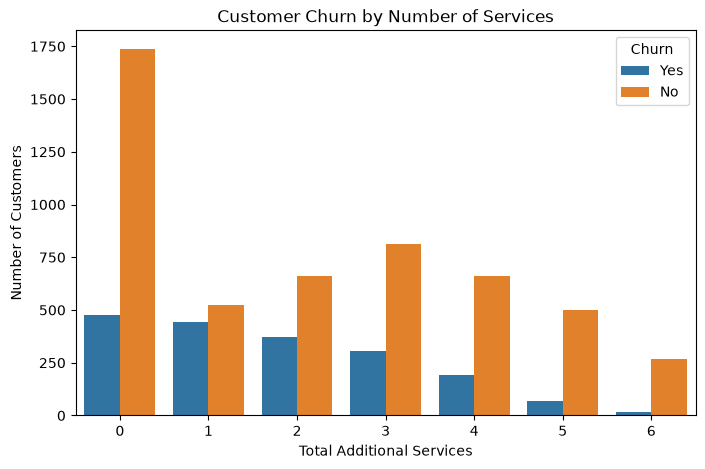

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TotalServices",
    hue="Churn"
)

plt.title("Customer Churn by Number of Services")
plt.xlabel("Total Additional Services")
plt.ylabel("Number of Customers")
plt.show()

## Check Churn Rate by Contract

In [38]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


## Check Churn Rate by Internet Service

In [39]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn_rate)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


## Check Churn Rate by Payment Method

In [40]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn_rate)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


## Check Churn Rate by Tenure Group

In [41]:
tenure_churn_rate = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn_rate)

Churn                No        Yes
TenureGroup                       
0-12 Months   52.321839  47.678161
13-24 Months  71.289062  28.710938
25-48 Months  79.611041  20.388959
49-72 Months  90.486824   9.513176


## Analyze Numerical Features by Churn

In [42]:
churn_numeric_summary = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean()

print(churn_numeric_summary)

          tenure  MonthlyCharges  TotalCharges
Churn                                         
No     37.650010       61.307408   2555.344141
Yes    17.979133       74.441332   1531.796094


## Feature Engineering

In [43]:
df_model = df.drop(
    columns=["customerID", "TenureGroup", "Churn"]
)

print("Model feature shape:", df_model.shape)
print(df_model.head())

Model feature shape: (7032, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   


## Separate Features and Target

In [44]:
X = df_model.copy()

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (7032, 20)
Target shape: (7032,)

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


## Identify Categorical Features

In [45]:
categorical_columns = X.select_dtypes(include=["object", "str"]).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Identify Numerical Features

In [46]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']


## Split the Dataset

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 20)
Testing features: (1407, 20)
Training target: (5625,)
Testing target: (1407,)


## Create the Preprocessing Pipeline

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## Train Logistic Regression

In [49]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (5625, 46)
Testing data shape: (1407, 46)


## Train Logistic Regression

In [50]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Make Predictions

In [51]:
y_pred = logistic_model.predict(X_test_processed)

print("Predictions generated successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions generated successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 1 0]


## Evaluate Logistic Regression

In [52]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.8031272210376688


## Train Random Forest

In [53]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


## Generate Random Forest Predictions

In [54]:
rf_pred = random_forest_model.predict(X_test_processed)

print("Random Forest predictions generated successfully!")
print("First 10 predictions:", rf_pred[:10])

Random Forest predictions generated successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 1 0]


## Evaluate Random Forest Accuracy

In [55]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.783226723525231


## Train XGBoost

In [56]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


## Generate XGBoost Predictions

In [57]:
xgb_pred = xgb_model.predict(X_test_processed)

print("XGBoost predictions generated successfully!")
print("First 10 predictions:", xgb_pred[:10])

XGBoost predictions generated successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 1 0]


## Evaluate XGBoost Accuracy

In [58]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.7938877043354655


## Compare All Three Models

In [59]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print(model_comparison)

                 Model  Accuracy
0  Logistic Regression  0.803127
1              XGBoost  0.793888
2        Random Forest  0.783227


## Classification Report for Logistic Regression

In [60]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:\n")
print(classification_report(y_test, y_pred))

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## Confusion Matrix

In [61]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[915 118]
 [159 215]]


## Visualize the Confusion Matrix

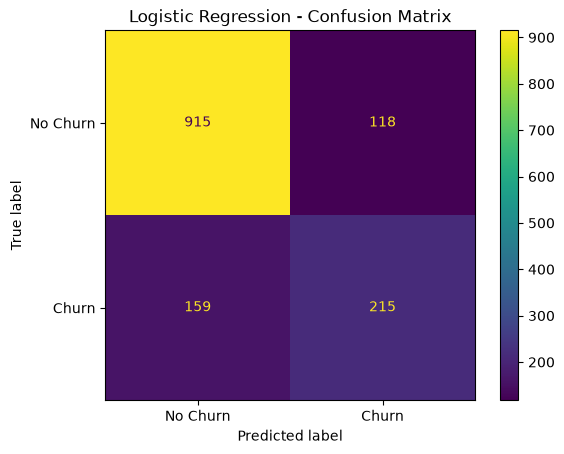

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

## Evaluate XGBoost Classification Report

In [63]:
print("XGBoost Classification Report:\n")
print(classification_report(y_test, xgb_pred))

XGBoost Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.54      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.79      0.79      1407



## Evaluate Random Forest Classification Report

In [64]:
print("Random Forest Classification Report:\n")
print(classification_report(y_test, rf_pred))

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1033
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407



## Select the Best Model

In [65]:
best_model = logistic_model
best_model_name = "Logistic Regression"

print("Best Model:", best_model_name)
print("Best Accuracy:", accuracy)

Best Model: Logistic Regression
Best Accuracy: 0.8031272210376688


## Save the Best Model

In [66]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/logistic_regression_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


## Save the Preprocessor

In [67]:
joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [68]:
import sys
sys.path.insert(0, "../src")

from predict import predict_churn

print("Prediction function imported successfully!") 

Prediction function imported successfully!


In [69]:
test_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 55.0,
    "TotalCharges": 275.0,
    "TotalServices": 1
}])

print("Test customer created successfully!")
print(test_customer)

Test customer created successfully!
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       5          Yes   

  MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection  \
0            No             DSL             No          Yes               No   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   

      PaymentMethod  MonthlyCharges  TotalCharges  TotalServices  
0  Electronic check            55.0         275.0              1  


In [70]:
prediction, probability = predict_churn(test_customer)

print("Prediction:", prediction)
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: 0
Churn Probability: 43.29 %


In [71]:
if prediction == 1:
    result = "Customer is likely to churn."
else:
    result = "Customer is unlikely to churn."

print("Prediction Result:", result)
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction Result: Customer is unlikely to churn.
Churn Probability: 43.29 %
